# Slide 19: the KBM dataset, median $\gamma_{\rm code}/\gamma_{\rm GS2}$ against WIDTH (TGLF top, GFTM bottom)

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). Slide 18 for the dataset. Format of `fig7_gamma_ratio` in
`notebooks/GFTM_numerics/kbm_width_ushape.ipynb` (branch `analysis/kbm-width-collapse`, qp5.27) with the user's changes: raw medians
only (no Gaussian overlay, no Galerkin), fewer NBASIS.

- Population: GS2-KBM samples (user classifier) of the SPR-045 / M1 `kbm_8d` hypercubes, 119 / 161 (as qp5.21, qp5.27, slide 9).
- TGLF `TGLF/Runs/kbm_tglf_nbasis/<db>/nb<N>_nx32_fp2p0_<w>`: FILTER 2, NBASIS_MAX 8/16/32, NXGRID 32, 24 widths.
- GFTM (stock field solve) `GFTM/Runs/LATIN_HYPERCUBE/<db>/kbm_8d/{wo_f05_<w>, qx_f05_<w>_nb<N>_nx<X>}`: FILTER 0.5, the existing
  NBASIS closest to 8/16/32/64: 11, 22, 43, 59 (NXGRID 17/28/49/65).
- Median over the population per (code, database, NBASIS, WIDTH); a case where the code finds no unstable mode counts as ratio 0.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# slide-readable at the saved size, white background (user, 2026-11-01)
plt.rcParams.update({"font.size": 20, "axes.labelsize": 22, "axes.titlesize": 22, "xtick.labelsize": 20, "ytick.labelsize": 20,
                     "legend.fontsize": 19, "lines.linewidth": 2.5, "lines.marker": "", "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white", "savefig.dpi": 200})
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import json
import re
from multiprocessing import get_context
import pandas as pd
from pyrokinetics import PyroHypercube
from pyrokinetics.pyroscan import PyroScanGKOutput
from general_analysis import mode_classification as mc

data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
lhc = data_root / "GS2" / "Runs" / "LATIN_HYPERCUBE"
databases = ["SPR-045", "M1"]
tglf_nbasis = [8, 16, 32]                           # NXGRID 32
gftm_sections = {11: 17, 22: 28, 43: 49, 59: 65}    # NBASIS: NXGRID
n_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

In [2]:
gs2 = {}
for database in databases:
    gs2_dir = lhc / database / "kbm_8d"
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gs2_avg = gs2_avg_scan.gk_output.data
    names = gs2_avg.sample_name.values.astype(str)
    assert (gs2_scan.gk_output.data.sample_name.values.astype(str) == names).all()
    gamma_gs2 = gs2_avg.growth_rate.pint.dequantify().values.ravel()
    kbm = (np.asarray(mc.classify(mc.indicators(gs2_scan, gs2_scan.gk_output.data))) == "KBM") & np.isfinite(gamma_gs2) & (gamma_gs2 > 0)
    gs2[database] = dict(names=names[kbm], gamma=gamma_gs2[kbm], units=re.sub(r"_pyroscan_base\d+", "", str(gs2_avg.growth_rate.data.units)))
    print(database, "GS2-KBM:", kbm.sum())

SPR-045 GS2-KBM: 119


M1 GS2-KBM: 161


TGLF: one `PyroHypercube` per leaf (WIDTH is the source `wo_<w>` deck's own, NBASIS_MAX and FILTER are GyroRun's `code_flags`).
GFTM: the older `wo_f05` leaves have no `pyroscan.json`, so their `pyroscan.nc`/`cube.nc` is read through `PyroScanGKOutput`, as
`kbm_width_ushape.ipynb`.

In [3]:
def dominant_gamma(output, database):
    output = output.set_index(sample="sample_name").sel(sample=gs2[database]["names"])
    assert re.sub(r"_pyroscan_base\d+", "", str(output.growth_rate.data.units)) == gs2[database]["units"], "normalisations differ"
    growth = output.growth_rate.pint.dequantify().fillna(-np.inf).transpose("sample", "mode")
    return growth.isel(mode=growth.argmax("mode")).clip(min=0).values


def load_tglf(leaf):
    database = leaf.parent.name
    tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    assert float(flags["FILTER"]) == 2.0 and int(flags["NXGRID"]) == 32 and leaf.name.startswith(f"nb{flags['NBASIS_MAX']}_nx32_fp2p0_")
    return pd.DataFrame(dict(code="TGLF", database=database, nbasis=int(flags["NBASIS_MAX"]),
                             width=round(float(tglf_scan.base_pyro.gk_input.data["width"]), 4),
                             gamma_ratio=dominant_gamma(tglf_scan.gk_output.data, database) / gs2[database]["gamma"]))


def load_gftm(leaf):
    database = leaf.parent.parent.name
    nbasis = 22 if leaf.name.startswith("wo_f05_") else int(leaf.name.split("_nb")[1].split("_")[0])
    netcdf = leaf / "pyro_cube" / "cube.nc" if (leaf / "pyro_cube" / "cube.nc").is_file() else leaf / "pyroscan.nc"
    return pd.DataFrame(dict(code="GFTM", database=database, nbasis=nbasis, width=round(float(leaf.name.split("_")[2][1:].replace("p", ".")), 4),
                             gamma_ratio=dominant_gamma(PyroScanGKOutput.from_netcdf(netcdf).data, database) / gs2[database]["gamma"]))


tglf_leaves = [leaf for database in databases for nbasis in tglf_nbasis
               for leaf in sorted((data_root / "TGLF" / "Runs" / "kbm_tglf_nbasis" / database).glob(f"nb{nbasis}_nx32_fp2p0_*"))]
gftm_dir = lambda database: data_root / "GFTM" / "Runs" / "LATIN_HYPERCUBE" / database / "kbm_8d"
gftm_leaves = [leaf for database in databases for leaf in sorted(gftm_dir(database).glob("wo_f05_w*")) +
               [leaf for nbasis, nxgrid in gftm_sections.items() if nbasis != 22 for leaf in sorted(gftm_dir(database).glob(f"qx_f05_w*_nb{nbasis}_nx{nxgrid}"))]]
with get_context("fork").Pool(n_workers) as pool:
    runs = pd.concat(pool.map(load_tglf, tglf_leaves, chunksize=2) + pool.map(load_gftm, gftm_leaves, chunksize=2), ignore_index=True)
medians = runs.groupby(["code", "database", "nbasis", "width"]).gamma_ratio.median().reset_index()
print(runs.groupby(["code", "database", "nbasis"]).width.nunique().unstack().to_string())

nbasis           8     11    16    22    32    43    59
code database                                          
GFTM M1         NaN  66.0   NaN  59.0   NaN  66.0  66.0
     SPR-045    NaN  66.0   NaN  59.0   NaN  66.0  66.0
TGLF M1        24.0   NaN  24.0   NaN  24.0   NaN   NaN
     SPR-045   24.0   NaN  24.0   NaN  24.0   NaN   NaN


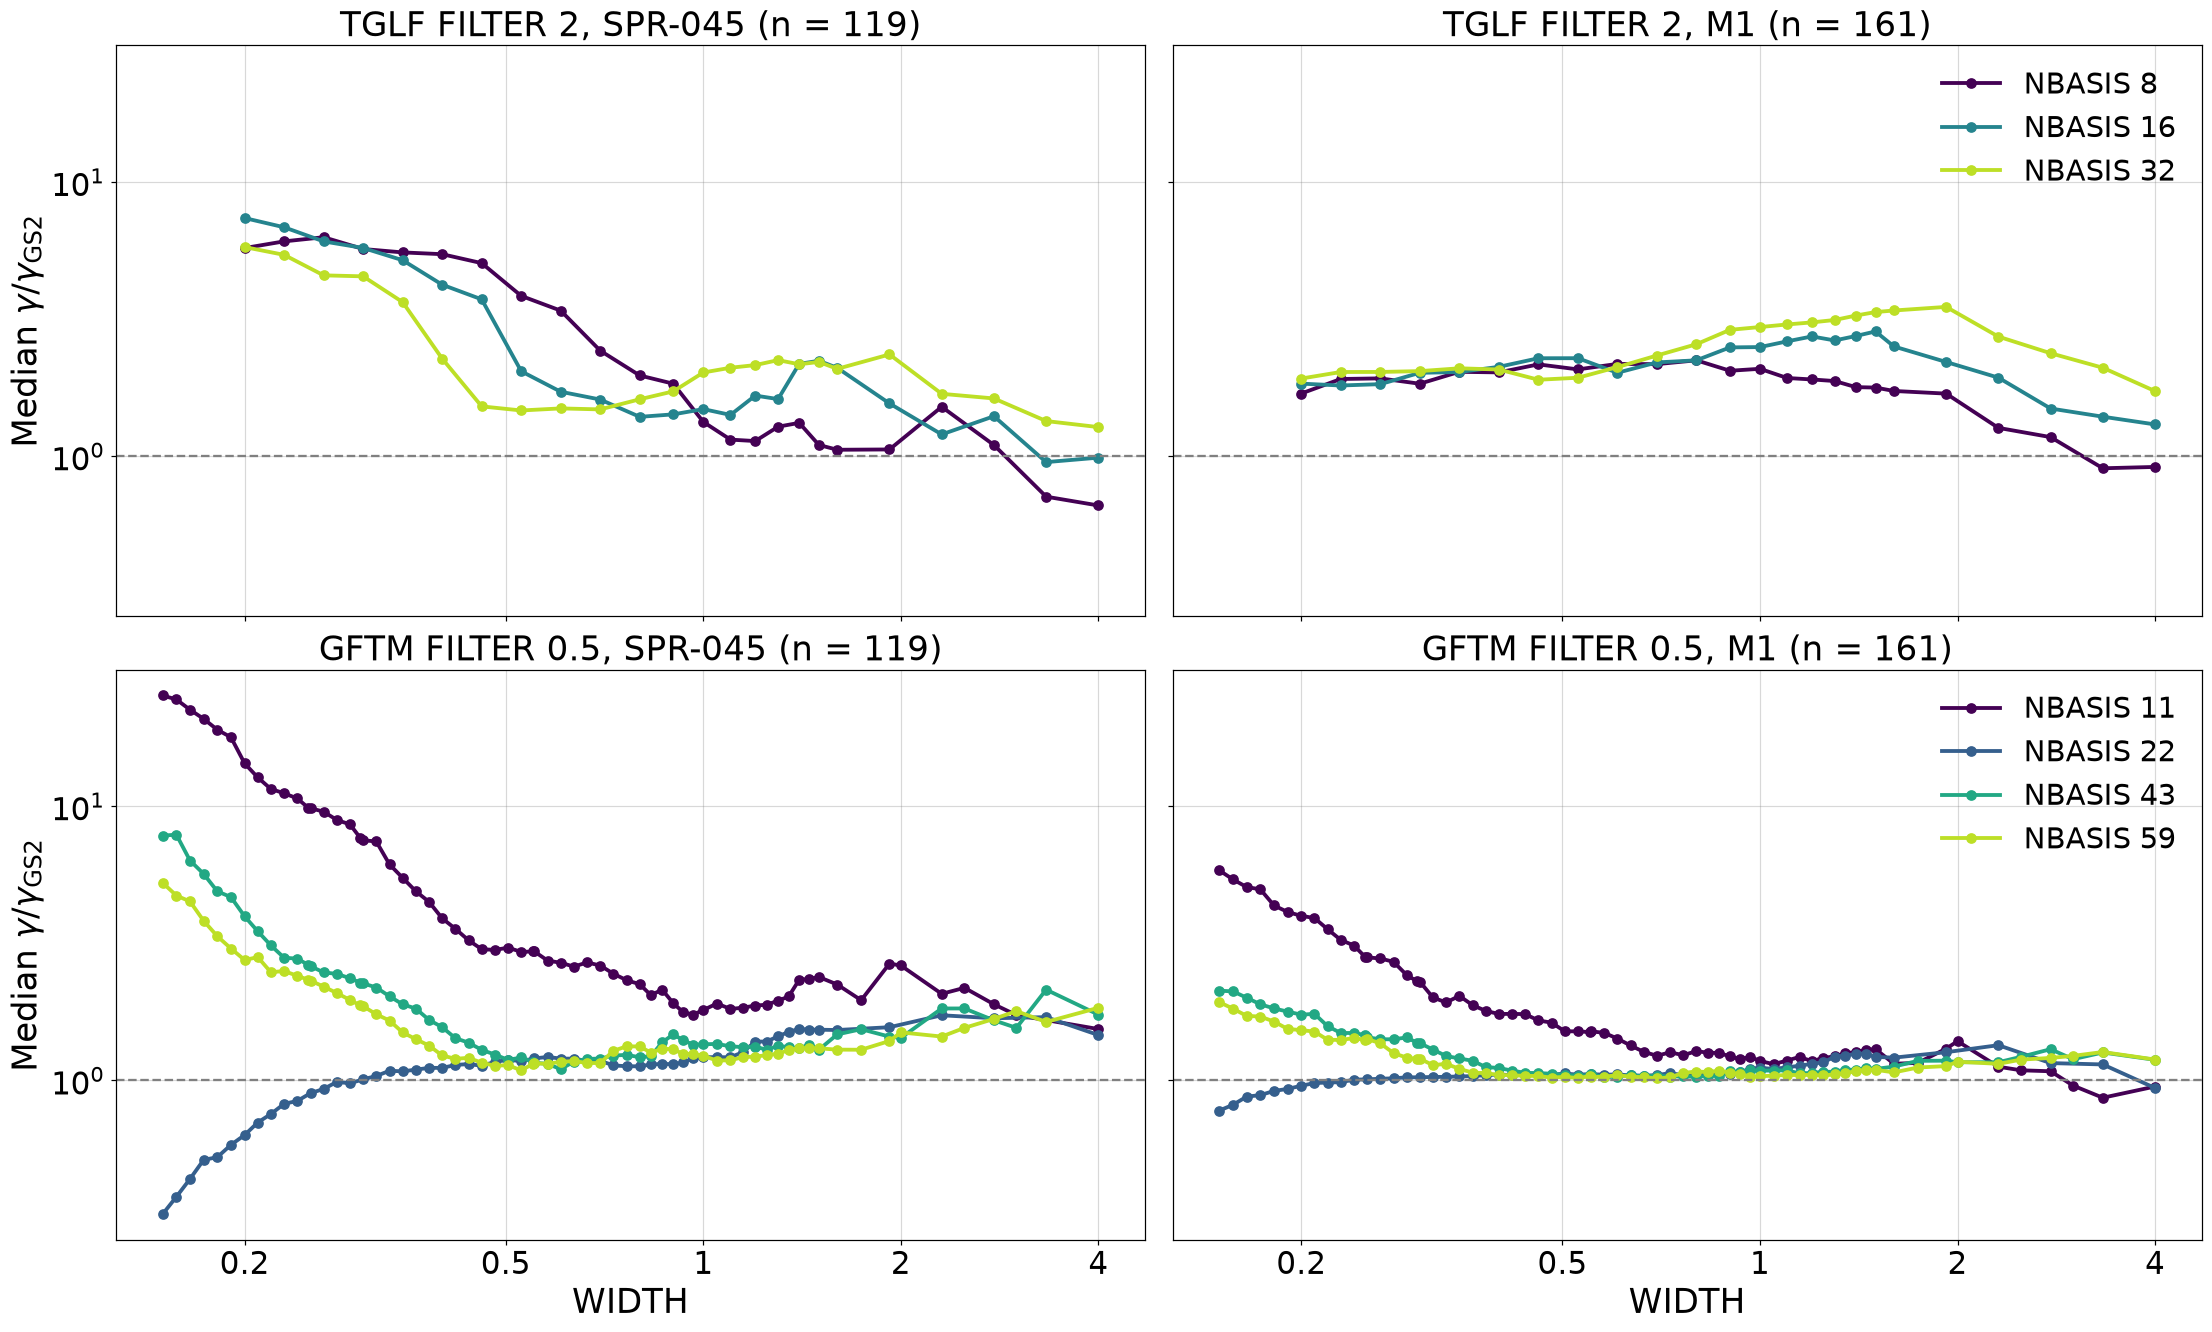

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharex=True, sharey=True)
for row, (code, nbasis_list) in enumerate((("TGLF", tglf_nbasis), ("GFTM", list(gftm_sections)))):
    colours = dict(zip(nbasis_list, plt.cm.viridis(np.linspace(0, 0.9, len(nbasis_list)))))
    for ax, database in zip(axes[row], databases):
        for nbasis in nbasis_list:
            line = medians[(medians.code == code) & (medians.database == database) & (medians.nbasis == nbasis)]
            ax.plot(line.width, line.gamma_ratio, color=colours[nbasis], marker="o", ms=6, label=f"NBASIS {nbasis}")
        ax.axhline(1.0, color="0.5", lw=1.5, ls="--")
        ax.set(xscale="log", yscale="log", title=f"{code} {'FILTER 2' if code == 'TGLF' else 'FILTER 0.5'}, {database} (n = {len(gs2[database]['names'])})")
        log_xticks(ax, [0.2, 0.5, 1, 2, 4])
    axes[row, 0].set_ylabel(r"Median $\gamma/\gamma_{\rm GS2}$")
    axes[row, 1].legend(loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("WIDTH")
fig.savefig(plots_dir / "fig_slide19_dataset_gamma_ratio.png", bbox_inches="tight")
plt.show()